# 🫀 Heart Disease Prediction with Random Forest
### Machine Learning Assignment — Random Forest Classification

---

**Dataset:** UCI Heart Disease Dataset (Cleveland Clinic Foundation)  
**Goal:** Predict whether a patient has heart disease based on clinical features  
**Skills Practiced:** EDA, Data Visualization, Random Forest, Model Evaluation, Feature Importance

---

## 📖 Dataset Description

This dataset contains **303 patient records** with **13 clinical features** collected from the Cleveland Clinic. Your goal is to predict the `target` column:
- `0` → No Heart Disease  
- `1` → Heart Disease Present

### Feature Dictionary

| Feature | Description |
|---|---|
| `age` | Age of the patient (years) |
| `sex` | Sex (1 = male, 0 = female) |
| `cp` | Chest pain type (0–3) |
| `trestbps` | Resting blood pressure (mm Hg) |
| `chol` | Serum cholesterol (mg/dl) |
| `fbs` | Fasting blood sugar > 120 mg/dl (1 = True, 0 = False) |
| `restecg` | Resting ECG results (0–2) |
| `thalach` | Maximum heart rate achieved |
| `exang` | Exercise-induced angina (1 = Yes, 0 = No) |
| `oldpeak` | ST depression induced by exercise relative to rest |
| `slope` | Slope of peak exercise ST segment (0–2) |
| `ca` | Number of major vessels colored by fluoroscopy (0–3) |
| `thal` | Thalassemia (1 = normal, 2 = fixed defect, 3 = reversible defect) |
| `target` | **Diagnosis** (1 = Heart Disease, 0 = No Disease) |

---

> ⚠️ **Instructions:** Complete each task below. Cells marked with `# YOUR CODE HERE` need your implementation.  
> 💡 Hints are provided in comments — read them carefully before writing code!

## 📦 Section 0: Import Libraries

In [1]:
# All required libraries are imported for you.
# Feel free to add more if needed!

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    roc_auc_score, roc_curve, ConfusionMatrixDisplay
)
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import plot_tree

import warnings
warnings.filterwarnings('ignore')

# Set a consistent style for all plots
sns.set_theme(style='whitegrid', palette='Set2')
plt.rcParams['figure.figsize'] = (10, 6)

print("✅ Libraries imported successfully!")

✅ Libraries imported successfully!


---
## 📂 Section 1: Load the Dataset

**Task 1.1** — Load the Heart Disease dataset and display the first few rows.

In [2]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
column_names = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg',
                'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']
df = pd.read_csv(url, names=column_names, na_values='?')
df.head()


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [3]:
df['target'] = (df['target'] > 0).astype(int)
print("Target counts:")
print(df['target'].value_counts())


Target counts:
target
0    164
1    139
Name: count, dtype: int64


---
## 🔍 Section 2: Exploratory Data Analysis (EDA)

Before building any model, always understand your data! Answer the questions below.

In [4]:
print("Shape:", df.shape)
print("\nData types:\n", df.dtypes)
print("\nMissing values:\n", df.isna().sum())
df.describe()


Shape: (303, 14)

Data types:
 age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
target        int64
dtype: object

Missing values:
 age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.458746
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,0.499120
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,1.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,1.000000


In [5]:
df = df.fillna(df.median())
print("Remaining missing values:", df.isna().sum().sum())


Remaining missing values: 0


---
## 📊 Section 3: Data Visualization

Create meaningful visualizations to understand the data. Each plot should have proper **titles**, **axis labels**, and **legends** where needed.

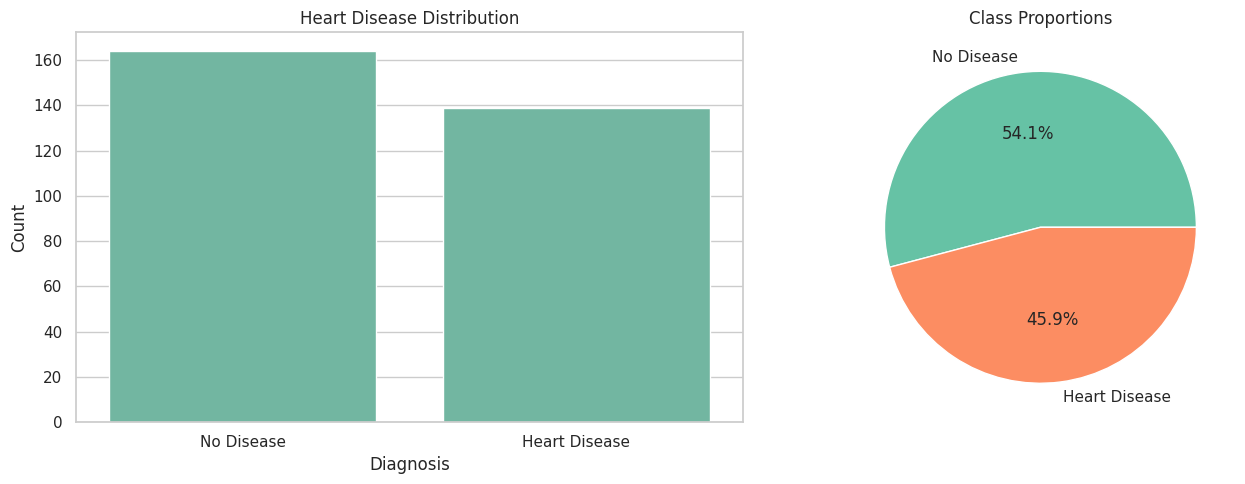

In [6]:
labels = ['No Disease', 'Heart Disease']
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=df, x='target', order=[0, 1], ax=axes[0])
axes[0].set(title='Heart Disease Distribution', xlabel='Diagnosis', ylabel='Count')
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(labels)
df['target'].value_counts().reindex([0, 1]).plot.pie(
    labels=labels, autopct='%1.1f%%', ax=axes[1], ylabel='', title='Class Proportions')
plt.tight_layout()
plt.show()


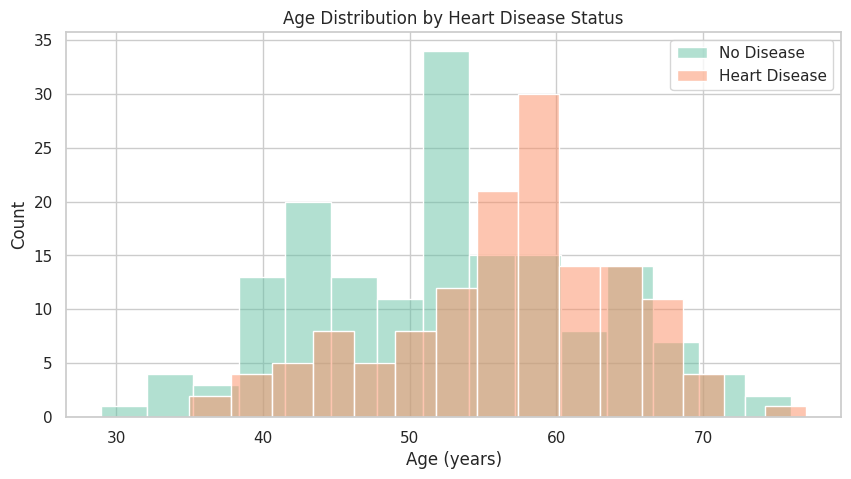

In [7]:
plt.figure(figsize=(10, 5))
for status, label in enumerate(labels):
    sns.histplot(df.loc[df['target'] == status, 'age'], bins=15,
                 alpha=0.5, label=label, color=sns.color_palette('Set2')[status])
plt.title('Age Distribution by Heart Disease Status')
plt.xlabel('Age (years)')
plt.ylabel('Count')
plt.legend()
plt.show()


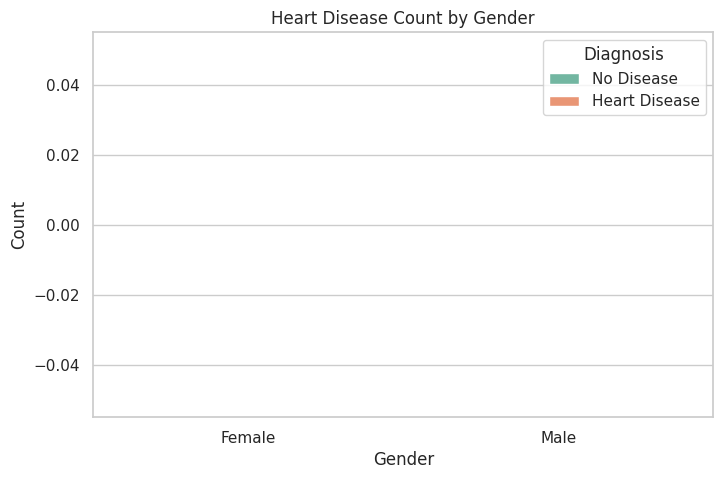

In [8]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='sex', hue='target', order=[0, 1], hue_order=[0, 1])
plt.title('Heart Disease Count by Gender')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.xticks([0, 1], ['Female', 'Male'])
handles, _ = plt.gca().get_legend_handles_labels()
plt.legend(handles, labels, title='Diagnosis')
plt.show()


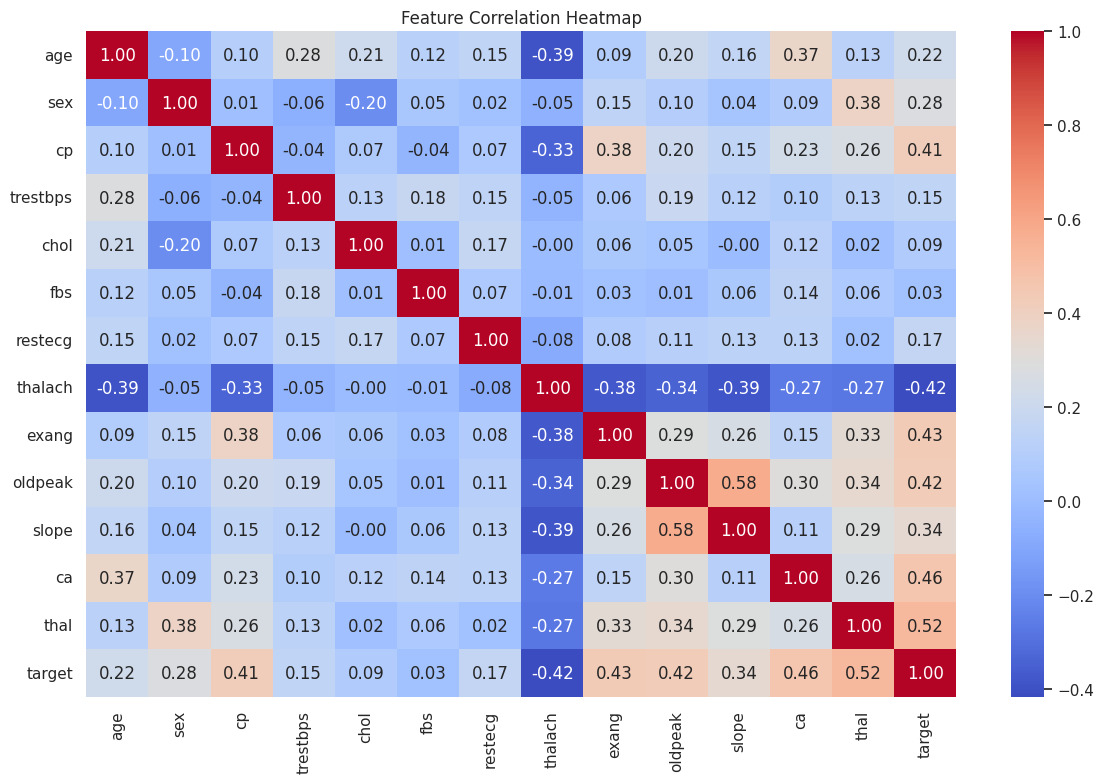

Highest positive target correlation: thal


In [9]:
corr = df.corr()
plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()
print("Highest positive target correlation:", corr['target'].drop('target').idxmax())


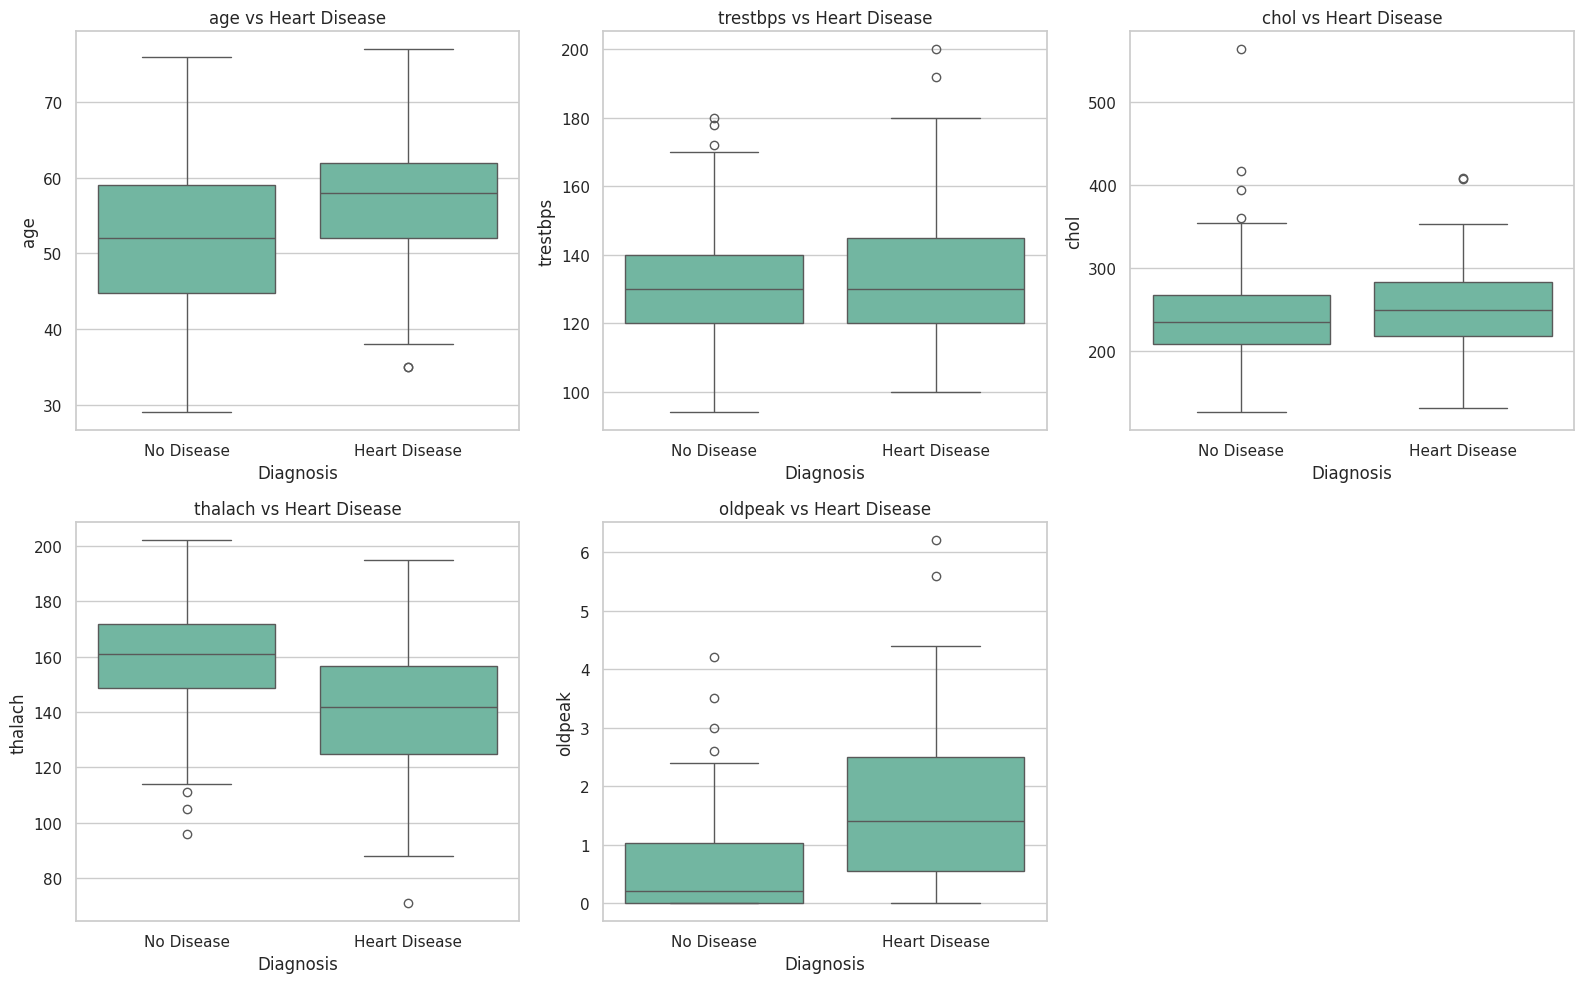

In [10]:
num_features = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()
for i, feature in enumerate(num_features):
    sns.boxplot(data=df, x='target', y=feature, order=[0, 1], ax=axes[i])
    axes[i].set(title=f'{feature} vs Heart Disease', xlabel='Diagnosis', ylabel=feature)
    axes[i].set_xticks([0, 1])
    axes[i].set_xticklabels(labels)
axes[-1].set_visible(False)
plt.tight_layout()
plt.show()


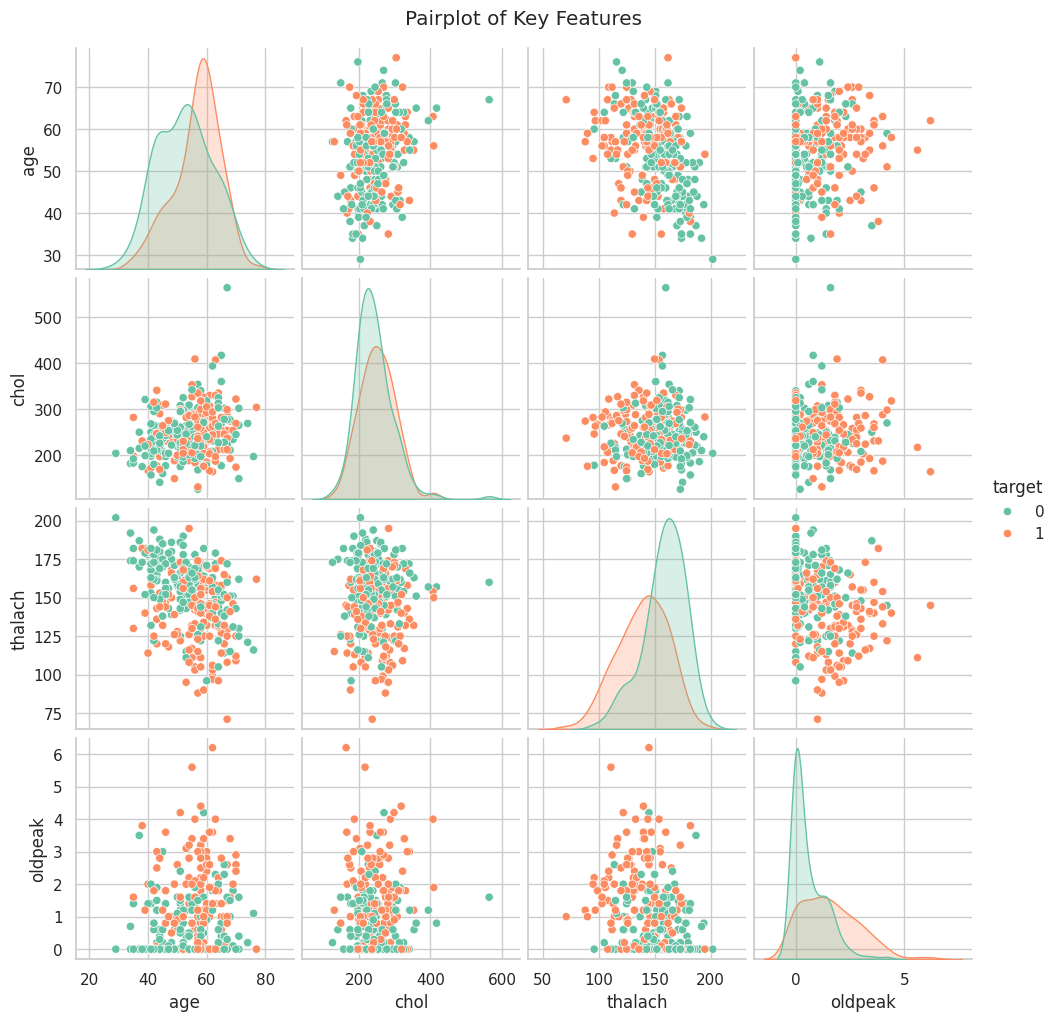

In [11]:
features = ['age', 'chol', 'thalach', 'oldpeak', 'target']
sns.pairplot(df[features], hue='target', diag_kind='kde')
plt.suptitle('Pairplot of Key Features', y=1.02)
plt.show()


---
## 🛠️ Section 4: Feature Preparation & Train-Test Split

In [12]:
X = df.drop(columns='target')
y = df['target']
print("Feature shape:", X.shape, "| Target shape:", y.shape)
print("Features:", list(X.columns))


Feature shape: (303, 13) | Target shape: (303,)
Features: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Training samples:", len(X_train), "| Test samples:", len(X_test))
print("Training class counts:\n", y_train.value_counts())


Training samples: 242 | Test samples: 61
Training class counts:
 target
0    131
1    111
Name: count, dtype: int64


---
## 🌲 Section 5: Random Forest — Building the Model

Now for the main event! Build, train, and evaluate a Random Forest classifier.

In [14]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
print("Random Forest trained with", rf_model.n_estimators, "trees.")


Random Forest trained with 100 trees.


In [15]:
y_pred = rf_model.predict(X_test)
train_acc = accuracy_score(y_train, rf_model.predict(X_train))
test_acc = accuracy_score(y_test, y_pred)
print(f"Training accuracy: {train_acc:.4f}")
print(f"Test accuracy: {test_acc:.4f}")
print(classification_report(y_test, y_pred, target_names=labels))


Training accuracy: 1.0000
Test accuracy: 0.8852
               precision    recall  f1-score   support

   No Disease       0.93      0.85      0.89        33
Heart Disease       0.84      0.93      0.88        28

     accuracy                           0.89        61
    macro avg       0.89      0.89      0.89        61
 weighted avg       0.89      0.89      0.89        61



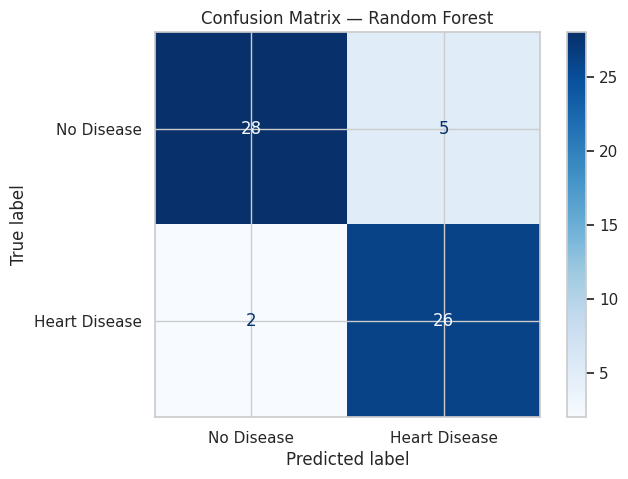

False positives: 5 | False negatives: 2


In [16]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap='Blues')
plt.title('Confusion Matrix — Random Forest')
plt.show()
print("False positives:", cm[0, 1], "| False negatives:", cm[1, 0])
# A false negative misses a patient with disease and can delay further assessment.


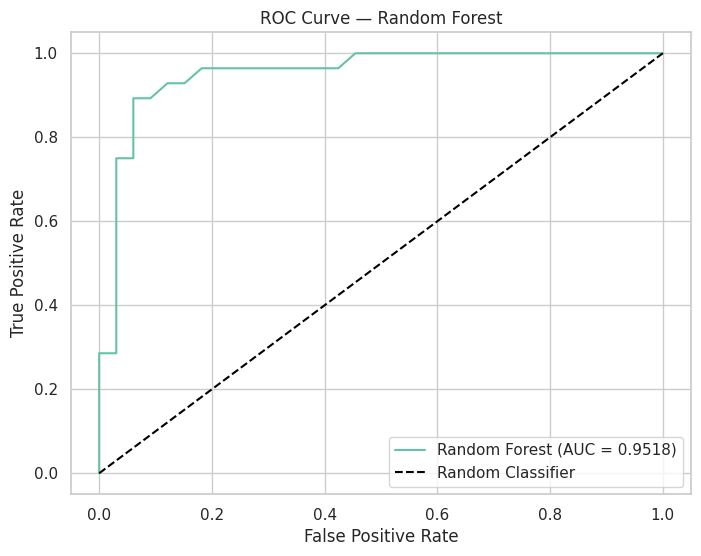

In [17]:
y_scores = rf_model.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_scores)
auc_score = roc_auc_score(y_test, y_scores)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'Random Forest (AUC = {auc_score:.4f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve — Random Forest')
plt.legend()
plt.show()


---
## 🔬 Section 6: Understanding the Forest — Feature Importance

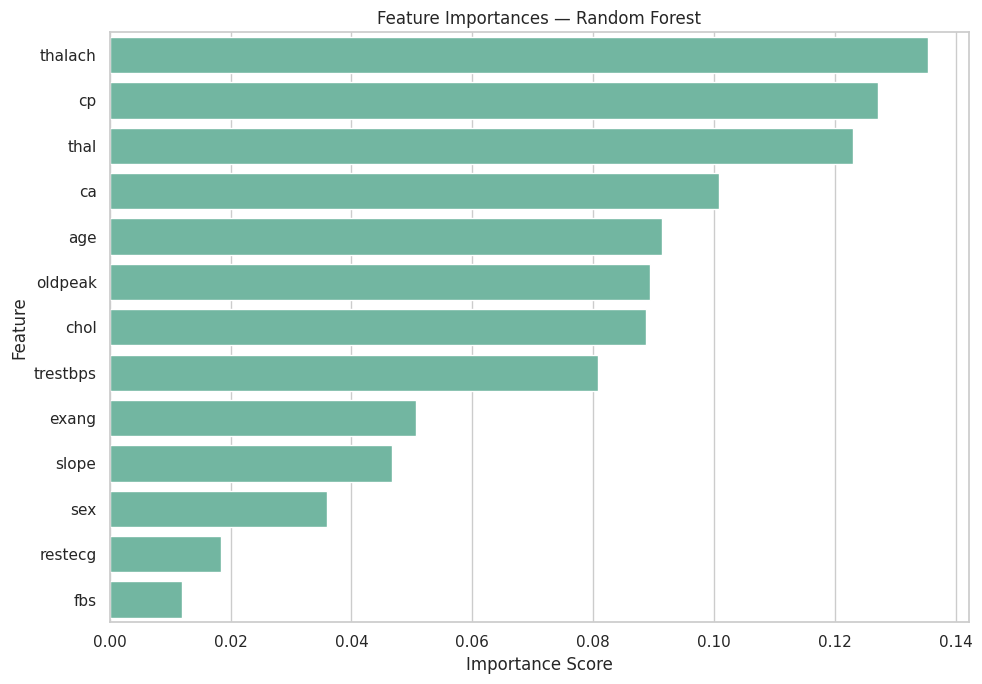

Top 3 features: thalach, cp, thal


In [18]:
importances = rf_model.feature_importances_
feature_names = X.columns
feat_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feat_df = feat_df.sort_values('Importance', ascending=False)
plt.figure(figsize=(10, 7))
sns.barplot(data=feat_df, x='Importance', y='Feature')
plt.title('Feature Importances — Random Forest')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()
print("Top 3 features:", ', '.join(feat_df.head(3)['Feature']))
# These are predictive associations, not evidence that a feature causes disease.


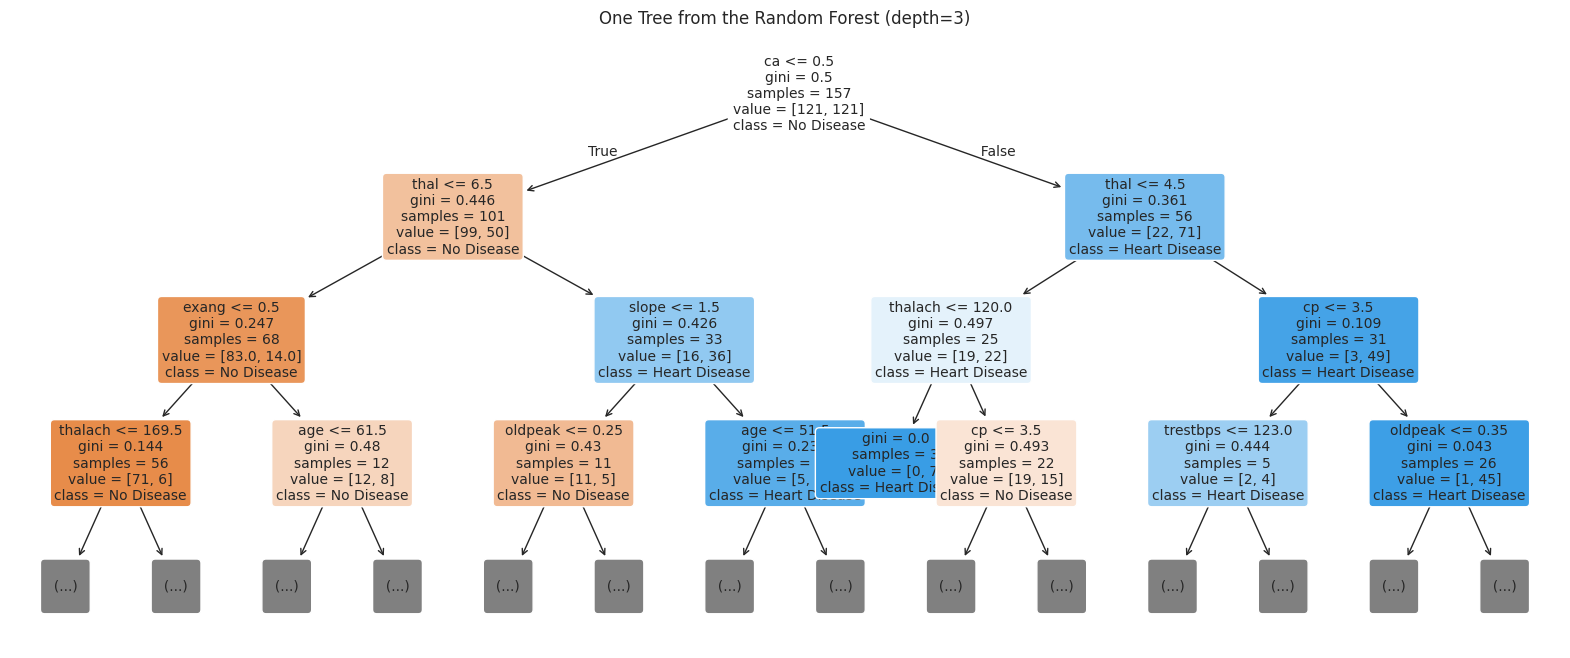

In [19]:
single_tree = rf_model.estimators_[0]
plt.figure(figsize=(20, 8))
plot_tree(single_tree, max_depth=3, feature_names=list(X.columns),
          class_names=labels, filled=True, rounded=True, fontsize=10)
plt.title('One Tree from the Random Forest (depth=3)')
plt.show()


---
## ⚙️ Section 7: Hyperparameter Tuning

A Random Forest has many knobs to tune. Let's find the best combination!

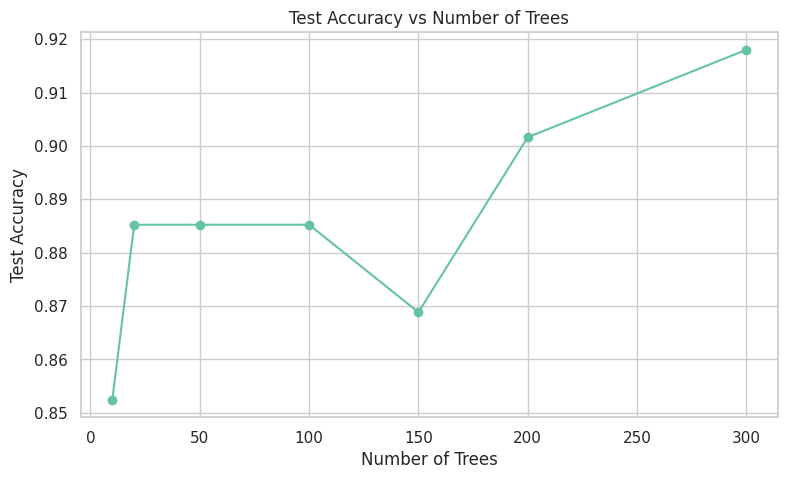

 Trees  Test accuracy
    10       0.852459
    20       0.885246
    50       0.885246
   100       0.885246
   150       0.868852
   200       0.901639
   300       0.918033


In [20]:
n_values = [10, 20, 50, 100, 150, 200, 300]
test_accuracies = []
for n in n_values:
    model = RandomForestClassifier(n_estimators=n, random_state=42)
    model.fit(X_train, y_train)
    test_accuracies.append(accuracy_score(y_test, model.predict(X_test)))
plt.figure(figsize=(9, 5))
plt.plot(n_values, test_accuracies, marker='o')
plt.xlabel('Number of Trees')
plt.ylabel('Test Accuracy')
plt.title('Test Accuracy vs Number of Trees')
plt.grid(True)
plt.show()
print(pd.DataFrame({'Trees': n_values, 'Test accuracy': test_accuracies}).to_string(index=False))


In [21]:
param_grid = {'n_estimators': [50, 100, 200],
              'max_depth': [None, 5, 10, 15],
              'min_samples_split': [2, 5, 10]}
grid_search = GridSearchCV(RandomForestClassifier(random_state=42),
                           param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train, y_train)
print("Best parameters:", grid_search.best_params_)
print(f"Best CV accuracy: {grid_search.best_score_:.4f}")


Best parameters: {'max_depth': 5, 'min_samples_split': 5, 'n_estimators': 100}
Best CV accuracy: 0.8344


In [22]:
best_model = grid_search.best_estimator_
y_pred_tuned = best_model.predict(X_test)
tuned_acc = accuracy_score(y_test, y_pred_tuned)
print(f"Baseline accuracy: {test_acc:.4f} | Tuned accuracy: {tuned_acc:.4f}")
print(f"Accuracy change: {(tuned_acc - test_acc) * 100:.2f} percentage points")


Baseline accuracy: 0.8852 | Tuned accuracy: 0.9016
Accuracy change: 1.64 percentage points


---
## 📉 Section 8: Cross-Validation

Cross-validation gives a more reliable estimate of model performance.

CV scores: [0.8361 0.8852 0.8197 0.8    0.7833]
Mean: 0.8249 | Standard deviation: 0.0350


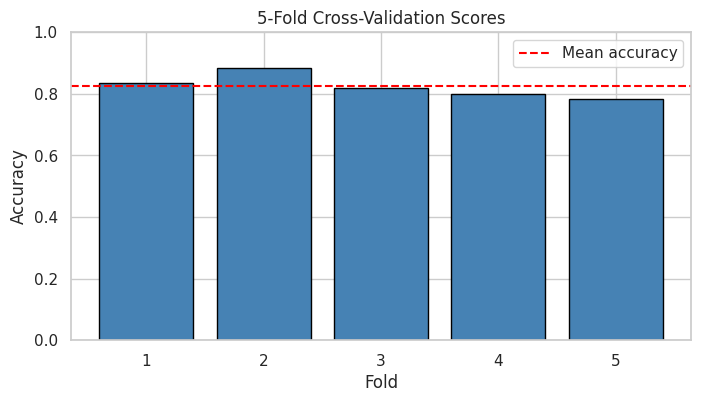

In [23]:
cv_scores = cross_val_score(best_model, X, y, cv=5, scoring='accuracy')
print("CV scores:", cv_scores.round(4))
print(f"Mean: {cv_scores.mean():.4f} | Standard deviation: {cv_scores.std():.4f}")
plt.figure(figsize=(8, 4))
plt.bar(range(1, 6), cv_scores, color='steelblue', edgecolor='black')
plt.axhline(cv_scores.mean(), color='red', linestyle='--', label='Mean accuracy')
plt.xlabel('Fold')
plt.ylabel('Accuracy')
plt.title('5-Fold Cross-Validation Scores')
plt.ylim(0, 1)
plt.legend()
plt.show()


---
## ✍️ Section 9: Reflection Questions

Answer the following questions in the markdown cells below. Write 2–4 sentences for each.

**Q1: What is the key difference between a single Decision Tree and a Random Forest?  
Why does the Random Forest typically perform better?**

A Decision Tree uses one tree to make predictions. A Random Forest combines the votes of many trees trained using different samples and feature choices. This usually makes predictions more reliable and reduces overfitting.

**Q2: What does "feature importance" mean in the context of a Random Forest?  
Which feature was most important in your model, and does it make clinical sense?**

Feature importance shows how much each feature helped the trees separate the classes. In this model, thalach (maximum heart rate achieved) was the most important feature, followed by cp and thal. This is reasonable because heart rate during exercise gives information about heart function, but importance does not prove that a feature causes disease.

**Q3: Your model may achieve very high training accuracy but slightly lower test accuracy.  
What is this phenomenon called, and how does Random Forest help mitigate it?**

This is called overfitting: the model learns the training data better than it handles new data. Here, training accuracy was 100%, while test accuracy was about 88.5%. Random Forest reduces overfitting by combining many different trees, and limiting tree depth can help further.

**Q4: In the medical context of heart disease prediction, which is more dangerous:  
a False Positive or a False Negative? How would you adjust your model to address this?**

A false negative can be more dangerous because it says a person has no disease when disease is actually present, which may delay care. This model produced 2 false negatives and 5 false positives on the test set. I would try a lower prediction threshold or give the disease class more weight, then check on validation data whether recall improves and how many extra false positives this creates.

---
## 🌟 BONUS Section: Challenge Tasks

If you've finished everything above, try these extra challenges!

In [24]:
from sklearn.base import clone
top_features = feat_df.head(7)['Feature'].tolist()
X_top = X[top_features]
X_top_train, X_top_test = X_train[top_features], X_test[top_features]
selected_model = clone(best_model).fit(X_top_train, y_train)
selected_acc = accuracy_score(y_test, selected_model.predict(X_top_test))
print("Selected features:", top_features)
print(f"All features: {tuned_acc:.4f} | Top 7 features: {selected_acc:.4f}")


Selected features: ['thalach', 'cp', 'thal', 'ca', 'age', 'oldpeak', 'chol']
All features: 0.9016 | Top 7 features: 0.8852


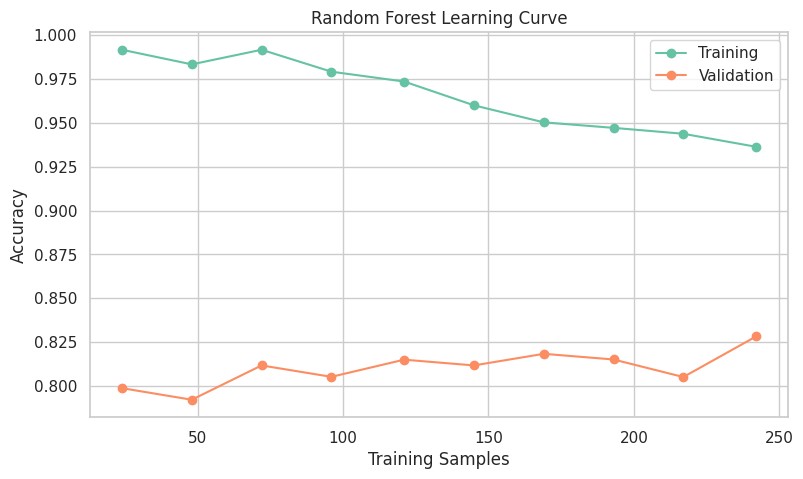

In [25]:
from sklearn.model_selection import learning_curve
train_sizes, train_scores, val_scores = learning_curve(
    best_model, X, y, cv=5, scoring='accuracy',
    train_sizes=np.linspace(0.1, 1.0, 10), shuffle=True, random_state=42, n_jobs=-1)
plt.figure(figsize=(9, 5))
plt.plot(train_sizes, train_scores.mean(axis=1), 'o-', label='Training')
plt.plot(train_sizes, val_scores.mean(axis=1), 'o-', label='Validation')
plt.xlabel('Training Samples')
plt.ylabel('Accuracy')
plt.title('Random Forest Learning Curve')
plt.legend()
plt.grid(True)
plt.show()


Decision Tree: accuracy=0.7377, ROC-AUC=0.7440
Random Forest: accuracy=0.9016, ROC-AUC=0.9481


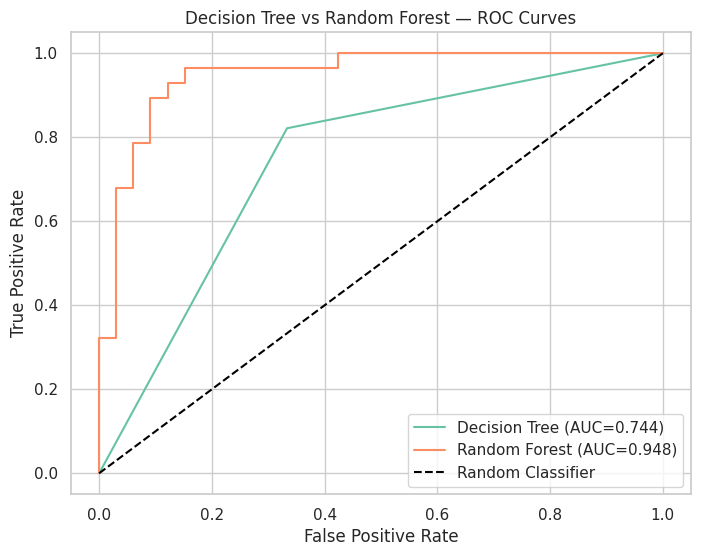

In [26]:
from sklearn.tree import DecisionTreeClassifier
tree_model = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
plt.figure(figsize=(8, 6))
for name, model in [('Decision Tree', tree_model), ('Random Forest', best_model)]:
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]
    accuracy = accuracy_score(y_test, predictions)
    auc = roc_auc_score(y_test, probabilities)
    print(f"{name}: accuracy={accuracy:.4f}, ROC-AUC={auc:.4f}")
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    plt.plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Decision Tree vs Random Forest — ROC Curves')
plt.legend()
plt.show()


---
## 📋 Submission Checklist

Before submitting, make sure you have completed all of the following:

- [ ] Loaded and explored the dataset (Section 1 & 2)
- [ ] Handled missing values (Task 2.2)
- [ ] Created all 5 required visualizations (Section 3)
- [ ] Built and evaluated a baseline Random Forest model (Section 5)
- [ ] Plotted confusion matrix and ROC curve
- [ ] Analyzed feature importances (Section 6)
- [ ] Performed hyperparameter tuning with GridSearchCV (Section 7)
- [ ] Ran 5-fold cross-validation (Section 8)
- [ ] Answered all 4 reflection questions (Section 9)
- [ ] All plots have titles, axis labels, and legends
- [ ] Code is clean and well-commented

---
*Good luck! 🌲🌲🌲 Remember: A forest is always stronger than a single tree.*